In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from plotnine import (
    ggplot,
    aes,
    geom_point,
    geom_boxplot,
    geom_jitter,
    geom_smooth,
    facet_wrap,
    labs,
    theme_minimal
)

## Part 1

In [3]:
rng = np.random.default_rng(556)

In [4]:
n = 150

df = pd.DataFrame({
    "id": range(1, n + 1),
    "group": rng.choice(
        ["A", "B", "C"],
        size=n
    ),
    "age": rng.normal(
        loc=35,
        scale=10,
        size=n
    ),
    "baseline": rng.normal(
        loc=70,
        scale=12,
        size=n
    )
})

In [5]:
group_effect = df["group"].map({
    "A": 0,
    "B": 5,
    "C": -4
})

df["score"] = (
    40
    + 0.7 * df["baseline"]
    + 0.25 * df["age"]
    + group_effect
    + rng.normal(0, 8, size=n)
)

In [6]:
df["age"] = df["age"].round(1)

In [7]:
display(df.head())
print(df.shape, '\n')
print(df.dtypes, '\n')
print(df.describe(), '\n')

,id,group,age,baseline,score
0,1,B,36.0,80.334698,114.877174
1,2,C,37.6,56.352334,77.517082
2,3,A,52.4,61.420293,95.008105
3,4,A,40.3,75.626202,101.015205
4,5,C,31.6,66.805003,96.060058


(150, 5) 

id            int64
group           str
age         float64
baseline    float64
score       float64
dtype: object 

               id         age    baseline       score
count  150.000000  150.000000  150.000000  150.000000
mean    75.500000   33.914000   70.627972   98.390805
std     43.445368    9.806833   10.133623   12.290258
min      1.000000    6.600000   48.150404   75.384873
25%     38.250000   27.750000   63.472653   88.876482
50%     75.500000   33.800000   70.683625   98.095399
75%    112.750000   41.050000   78.207533  108.055134
max    150.000000   56.300000   96.520780  127.435702 



## Part 2

id: identifier, discrete numerical

group: categorical

age: continuos

baseline: continuos

score: continuos

## Part 3

In [8]:
df["score"].describe()

count    150.000000
mean      98.390805
std       12.290258
min       75.384873
25%       88.876482
50%       98.095399
75%      108.055134
max      127.435702
Name: score, dtype: float64

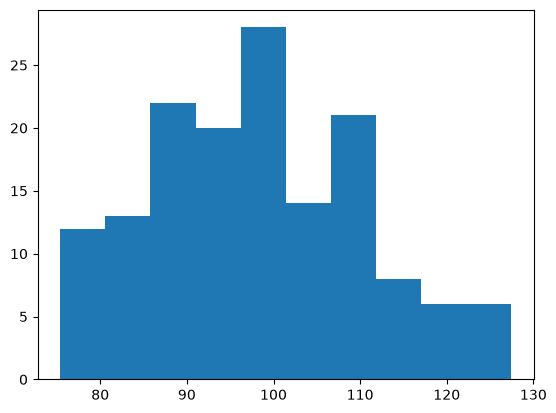

In [9]:
plt.hist(
    df["score"]
)

plt.show()

Questions

Where is the center?

The center is about 98

Is the distribution symmetric?

No

Are there unusual values?

There is a large number of observations around 110

What does the histogram reveal that describe() does not?

The distribution of the data. The data is not normally distributed.


## Part 4

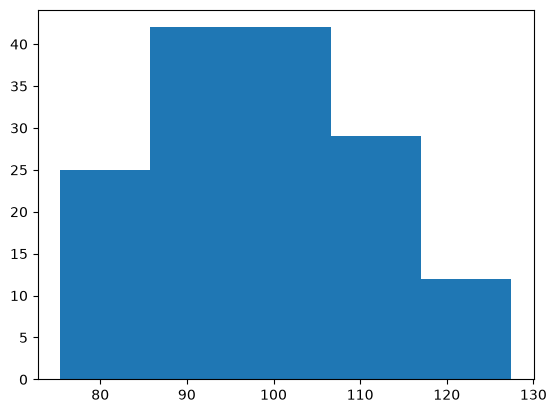

In [10]:
plt.hist(df["score"], bins=5)
plt.show()

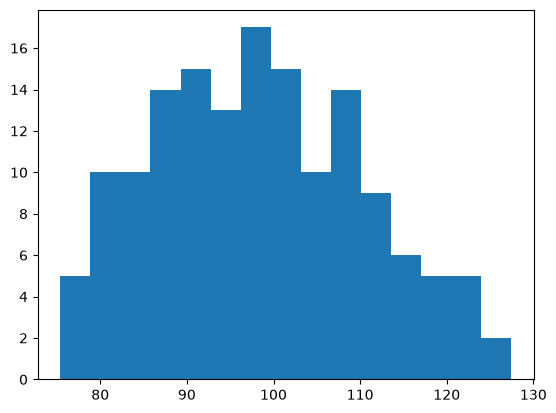

In [11]:
plt.hist(df["score"], bins=15)
plt.show()

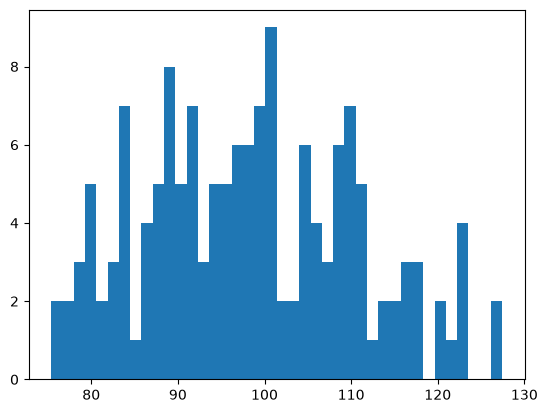

In [12]:
plt.hist(df["score"], bins=40)
plt.show()

How does the visual impression change? Is there one objectively correct number of bins?

The visual impression changes based on how many bins there are. If there are too many bins then there are gaps in the distribution and when the number of bins is too small there is not enough detail. The best option for this graph is 15 bins.

## Part 5

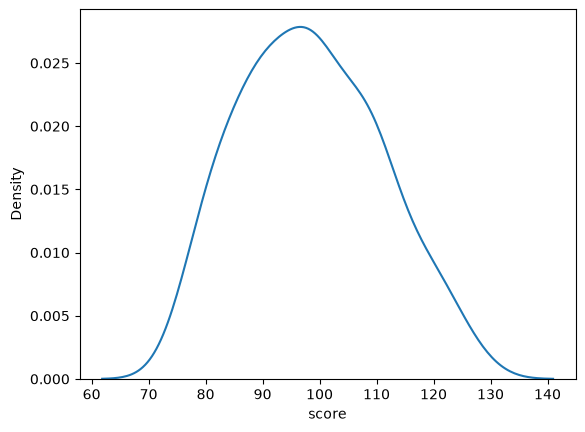

In [13]:
sns.kdeplot(
    data=df,
    x="score"
)

plt.show()

What features are easier to see?

It is easier to see the center of the data.

What information has been smoothed?

The heights between bars.

Why is this not the raw data?

It is a line fit to the distribution, it is not the raw data.

## Part 6

In [14]:
df["group"].value_counts()

group
A    58
C    48
B    44
Name: count, dtype: int64

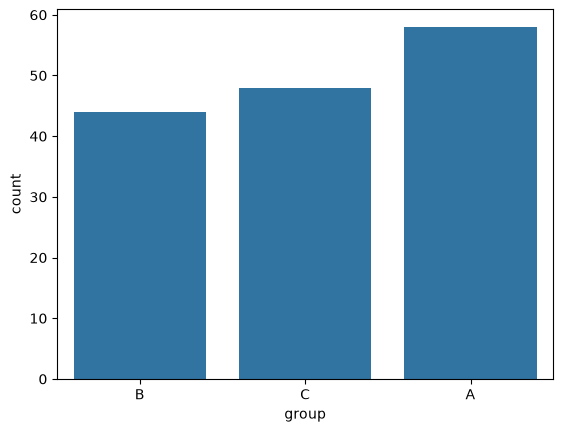

In [15]:
sns.countplot(
    data=df,
    x="group"
)

plt.show()

In [16]:
df["group"].value_counts(
    normalize=True
)

group
A    0.386667
C    0.320000
B    0.293333
Name: proportion, dtype: float64

Explain the difference between counts and proportions.

Proportion shows the percentage of the total data in each group.

## Part 7

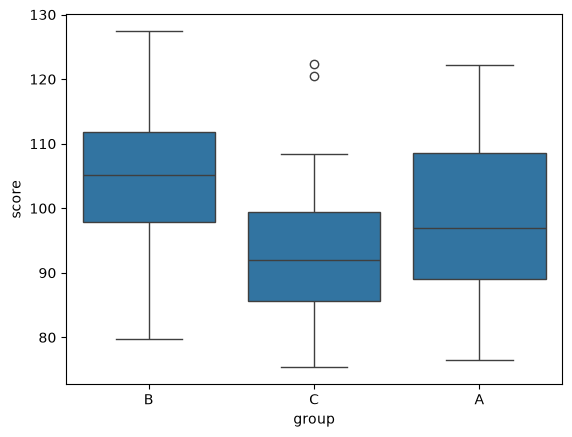

In [17]:
sns.boxplot(
    data=df,
    x="group",
    y="score"
)

plt.show()

Questions

Which group has the highest median?

Group B

Which appears most variable?

Group A

What information is hidden?

The density of the data.

## Part 8

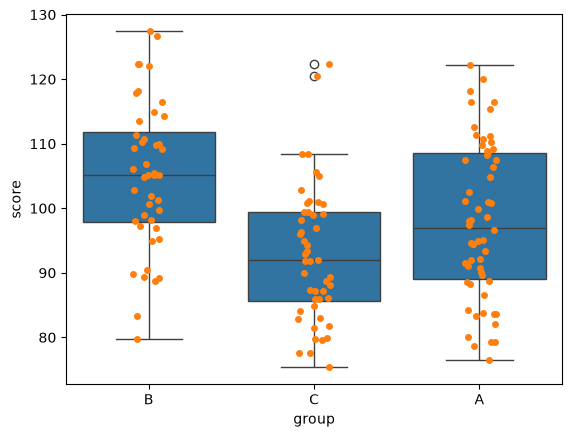

In [18]:
fig, ax = plt.subplots()

sns.boxplot(
    data=df,
    x="group",
    y="score",
    ax=ax
)

sns.stripplot(
    data=df,
    x="group",
    y="score",
    ax=ax
)

plt.show()

What becomes visible that was hidden by the boxplot?

We can now see the how much data is in a region. We can see the density.

## Part 9

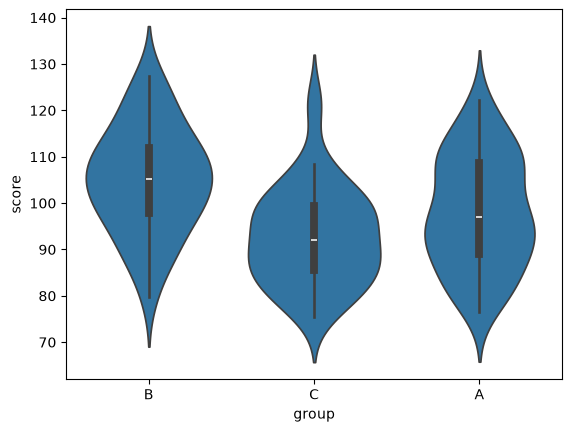

In [19]:
sns.violinplot(
    data=df,
    x="group",
    y="score"
)

plt.show()

Compare:

boxplot

violin plot

strip plot

Which representation best answers which question?

The boxplot shows the quartiles and min and max values. Good for a basic understand of the distribution. 

The violin plot shows the quartiles and the density of the data. Good if you want to know the density and distribution. 

The strip plot shows the boxplots and the actual data points. Good if you want to know the distribution and the value of observations.

## Part 10

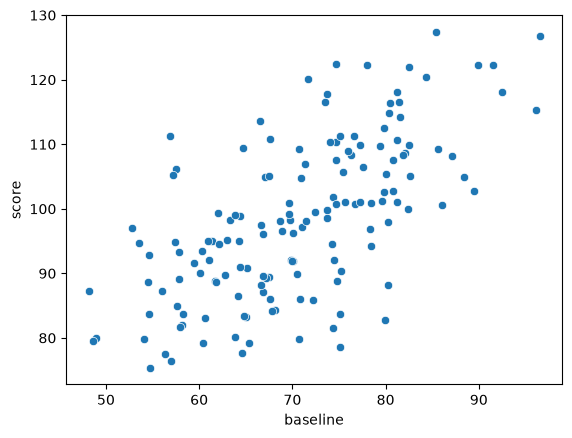

In [20]:
sns.scatterplot(
    data=df,
    x="baseline",
    y="score"
)

plt.show()

In [21]:
df[
    ["baseline", "score"]
].corr()

,baseline,score
baseline,1.000000,0.649576
score,0.649576,1.000000


Is the relationship approximately linear?

There is a positive linear relationship.

Are there outliers?

There does not appear to be any outliers.

Does variance appear constant?

The variance appears to be slightly smaller towards the tails.

What does the figure show that correlation does not?

The shape of the data.

## Part 13

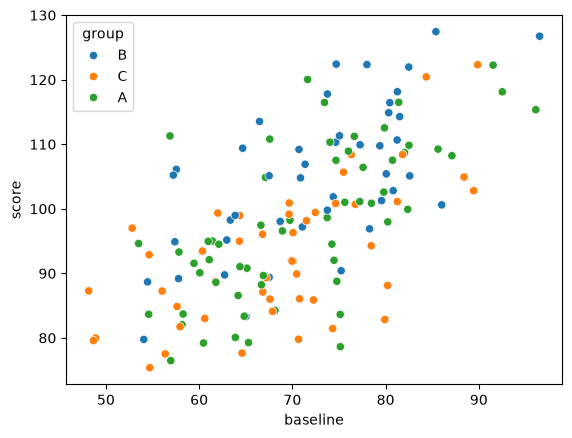

In [22]:
sns.scatterplot(
    data=df,
    x="baseline",
    y="score",
    hue="group"
)

plt.show()

What new statistical question can this figure address?

Do the groups have could change the relationship between baseline and score. The groups might have different slopes or variance.

## Part 12

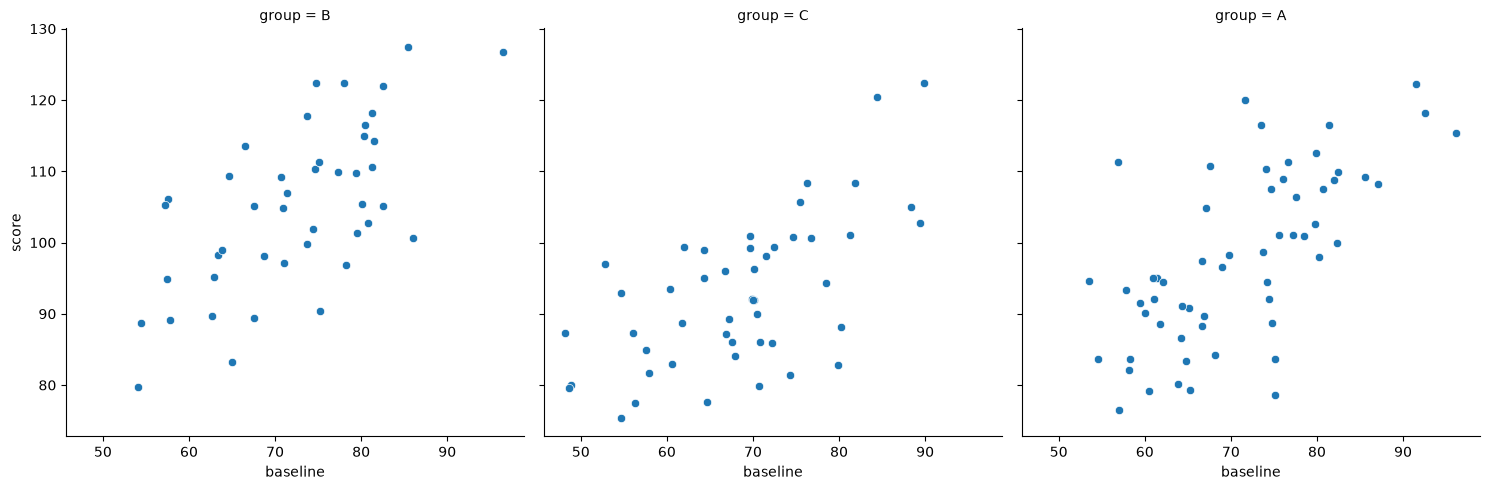

In [23]:
g = sns.relplot(
    data=df,
    x="baseline",
    y="score",
    col="group"
)

Compare faceting with color. When are separate panels easier to interpret?

If the levels appear to overlap a lot then separate panels are easier to interpret.

## Part 13

In [24]:
bad_rows = pd.DataFrame({
    "id": [151, 152],
    "group": ["A", "B"],
    "age": [999, 31],
    "baseline": [72, 300],
    "score": [82, 90]
})

In [25]:
dirty = pd.concat(
    [df, bad_rows],
    ignore_index=True
)

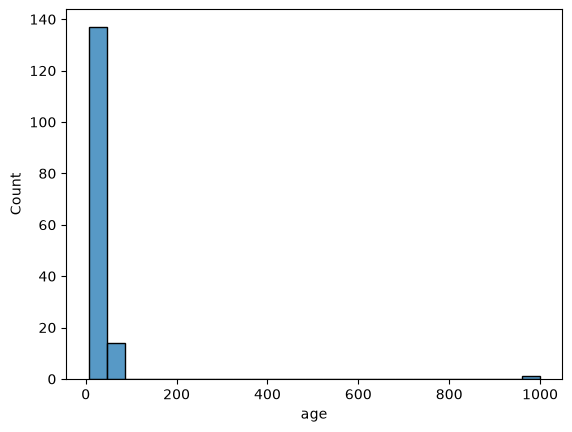

In [26]:
sns.histplot(
    data=dirty,
    x="age"
)

plt.show()

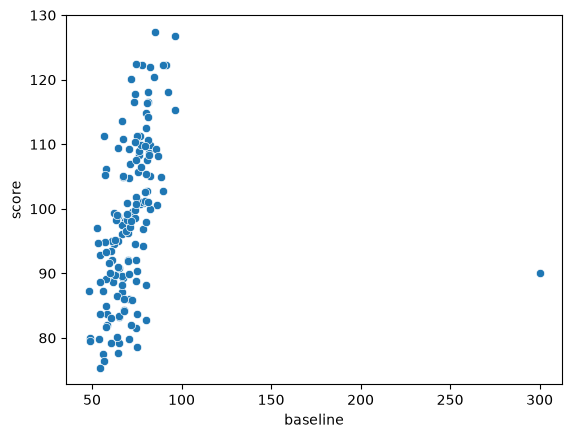

In [27]:
sns.scatterplot(
    data=dirty,
    x="baseline",
    y="score"
)

plt.show()

What problems become obvious visually?

The outliers makes it difficult to see the distribution and the relationship between variables.

In [28]:
dirty.loc[
    dirty["age"] > 120
]

,id,group,age,baseline,score
150,151,A,999.0,72.0,82.0


In [29]:
dirty.loc[
    dirty["baseline"] > 150
]

,id,group,age,baseline,score
151,152,B,31.0,300.0,90.0


How does visualization complement explicit validation rules?

Helps identifiy potentially incorrect data or data that could affect summary statistics.

## Part 15

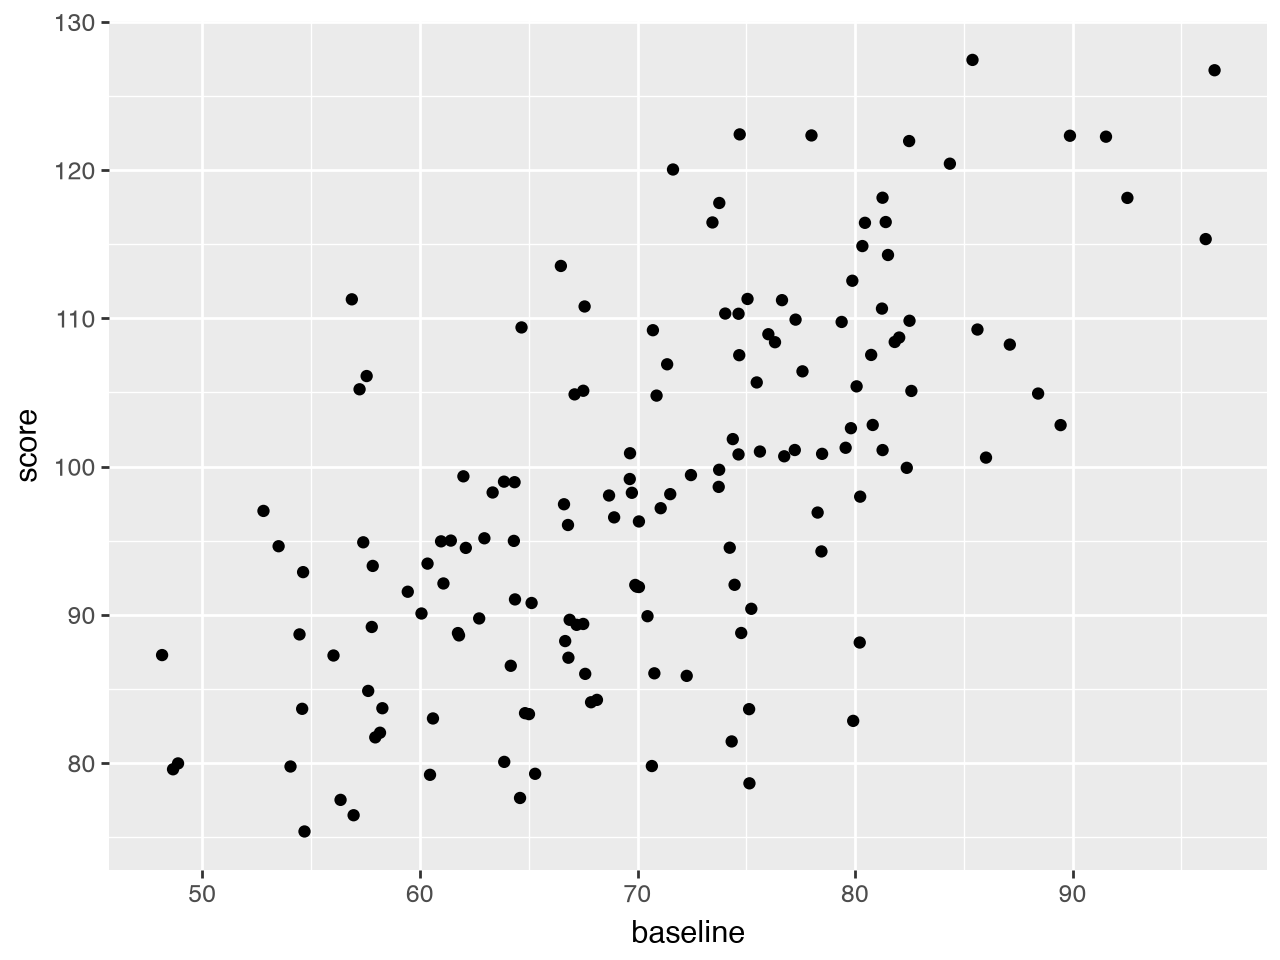

In [30]:
(
    ggplot(
        df,
        aes(
            x="baseline",
            y="score"
        )
    )
    + geom_point()
)

data: df

x aesthetic: baseline

y aesthetic: score

geometry: scatterplot


## Part 16

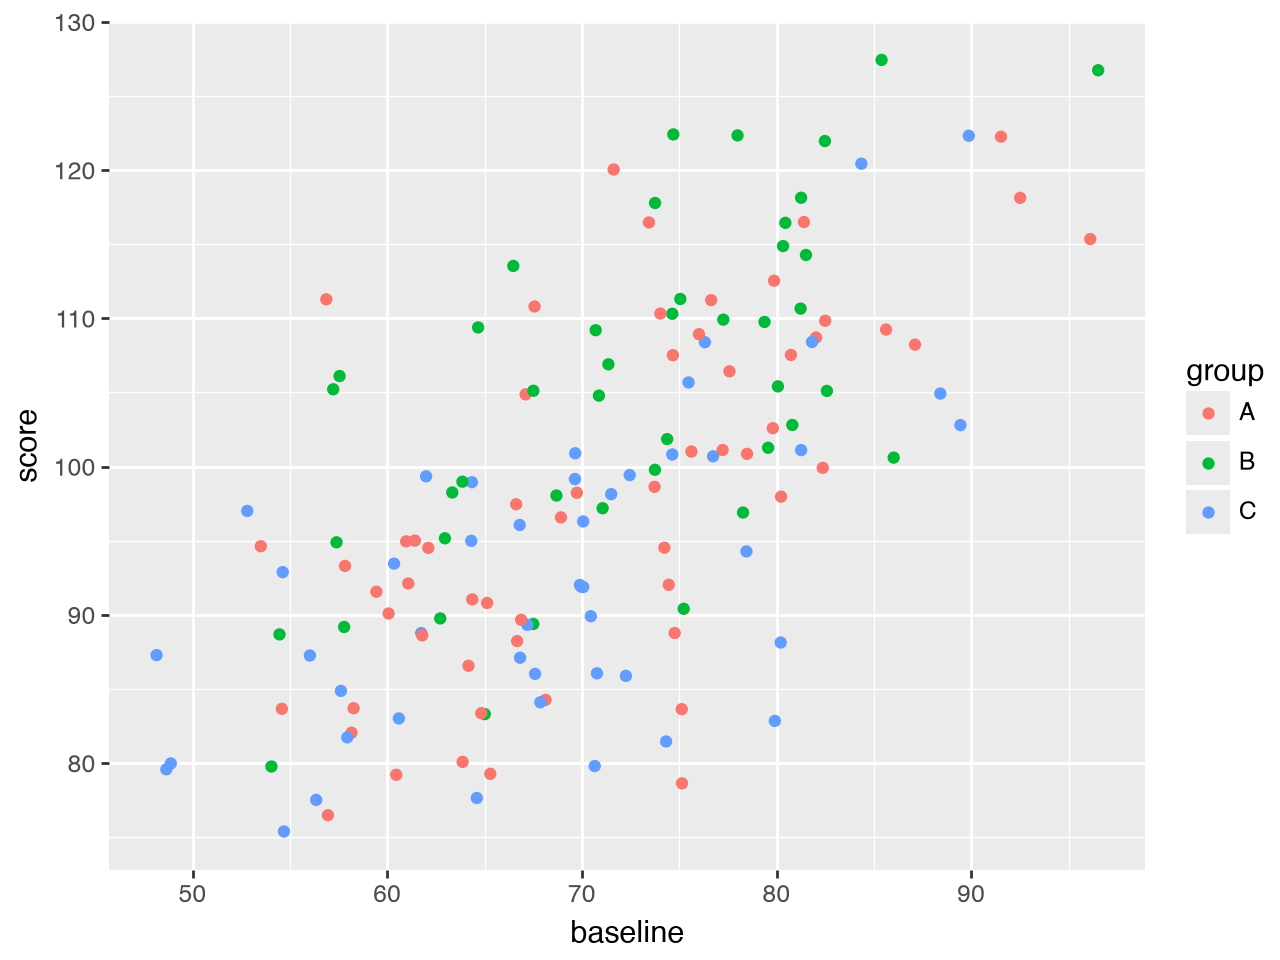

In [31]:
(
    ggplot(
        df,
        aes(
            x="baseline",
            y="score",
            color="group"
        )
    )
    + geom_point()
)

It colors the points by group

## Part 17

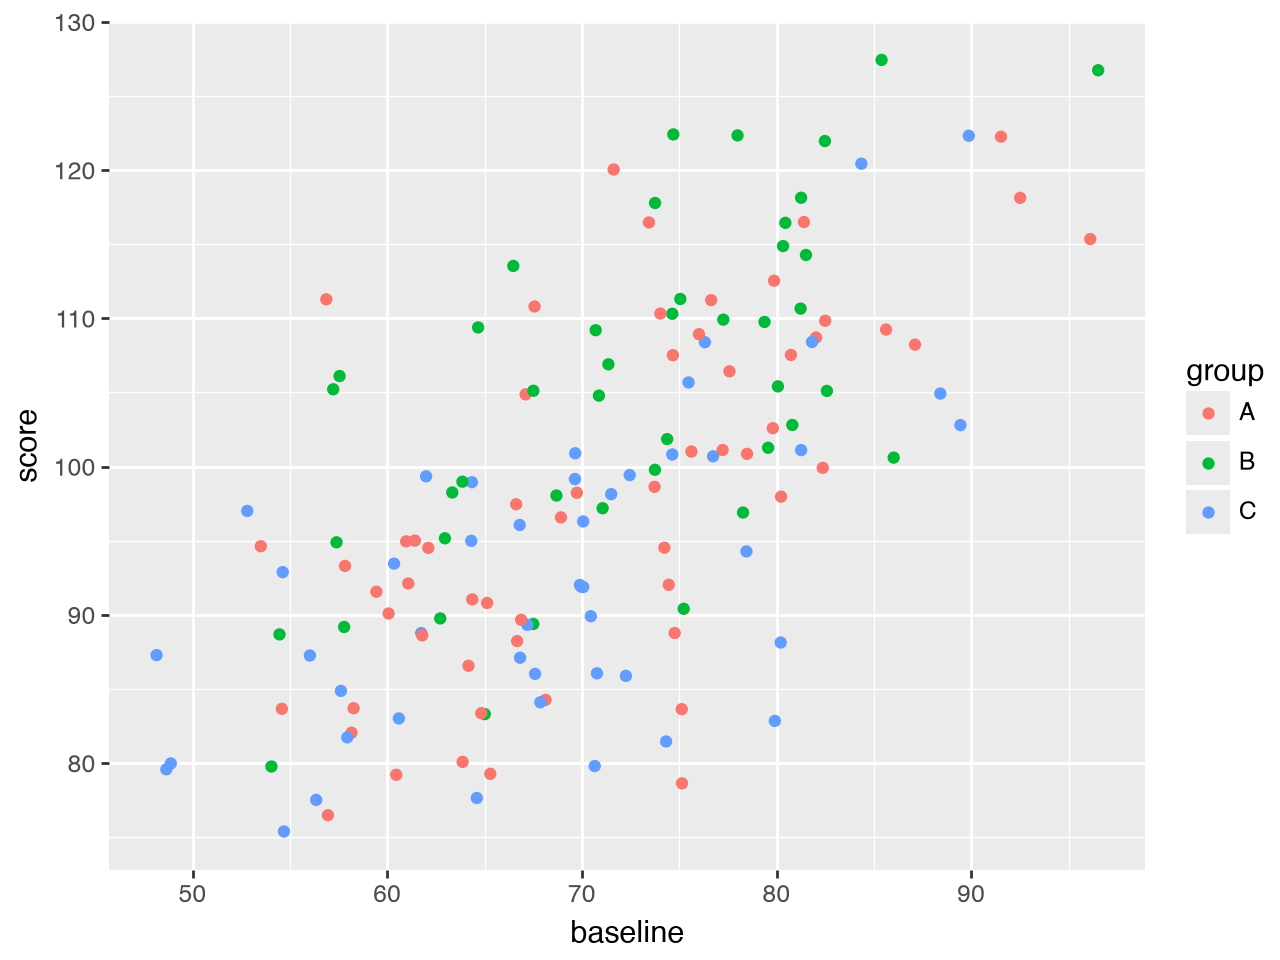

In [32]:
(
    ggplot(
        df,
        aes(
            x="baseline",
            y="score",
            color="group"
        )
    )
    + geom_point()
)

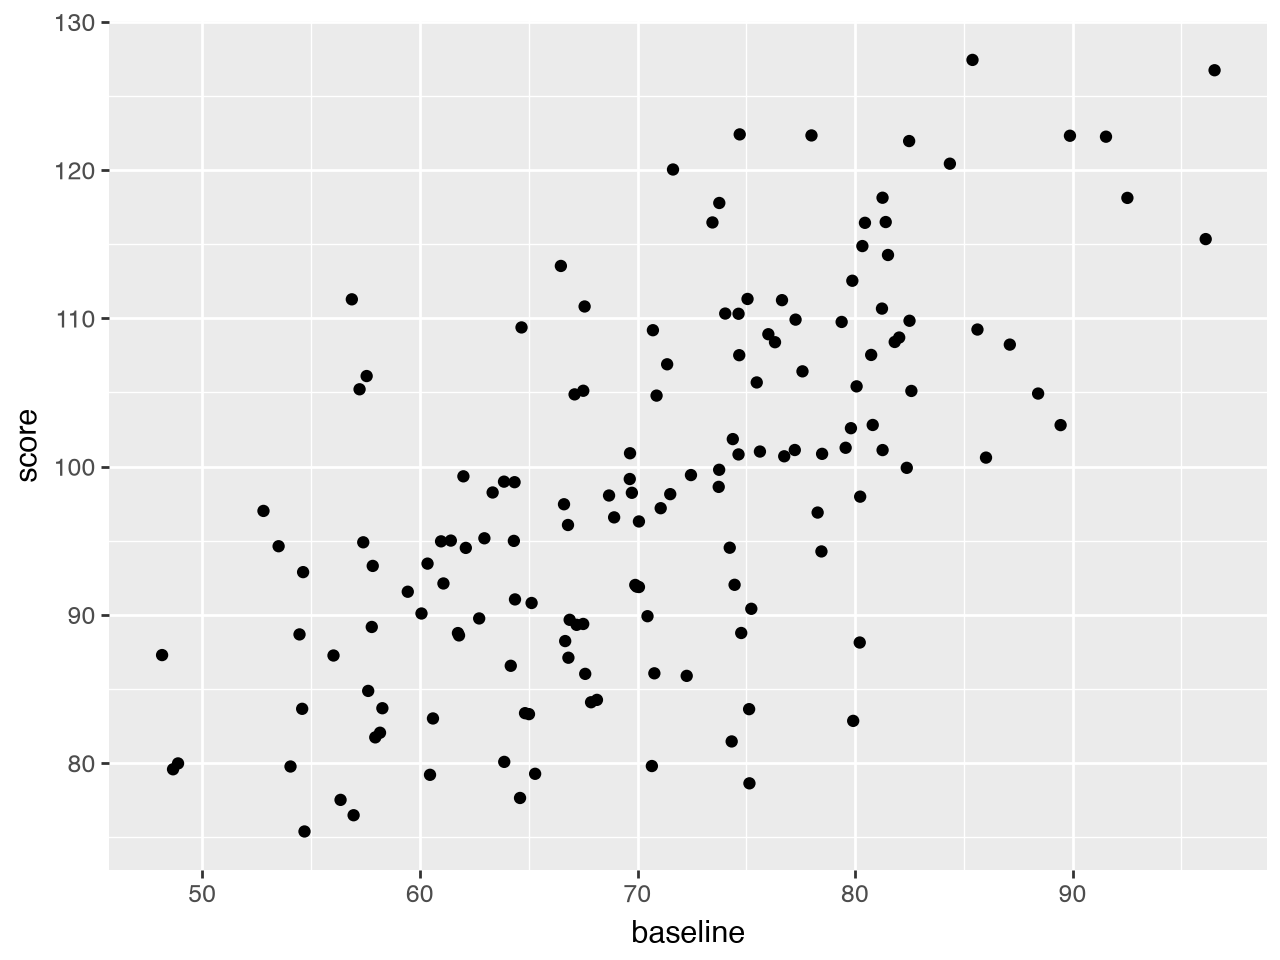

In [33]:
(
    ggplot(
        df,
        aes(
            x="baseline",
            y="score"
        )
    )
    + geom_point(
        color="black"
    )
)

Mapped colors color points based on a variable value while fixed color colors all points the same.

## Part 18

/Users/gracesonmule/Desktop/STA556/.sta556/lib/python3.12/site-packages/plotnine/stats/smoothers.py:342: PlotnineWarning: Confidence intervals are not yet implemented for lowess smoothings.


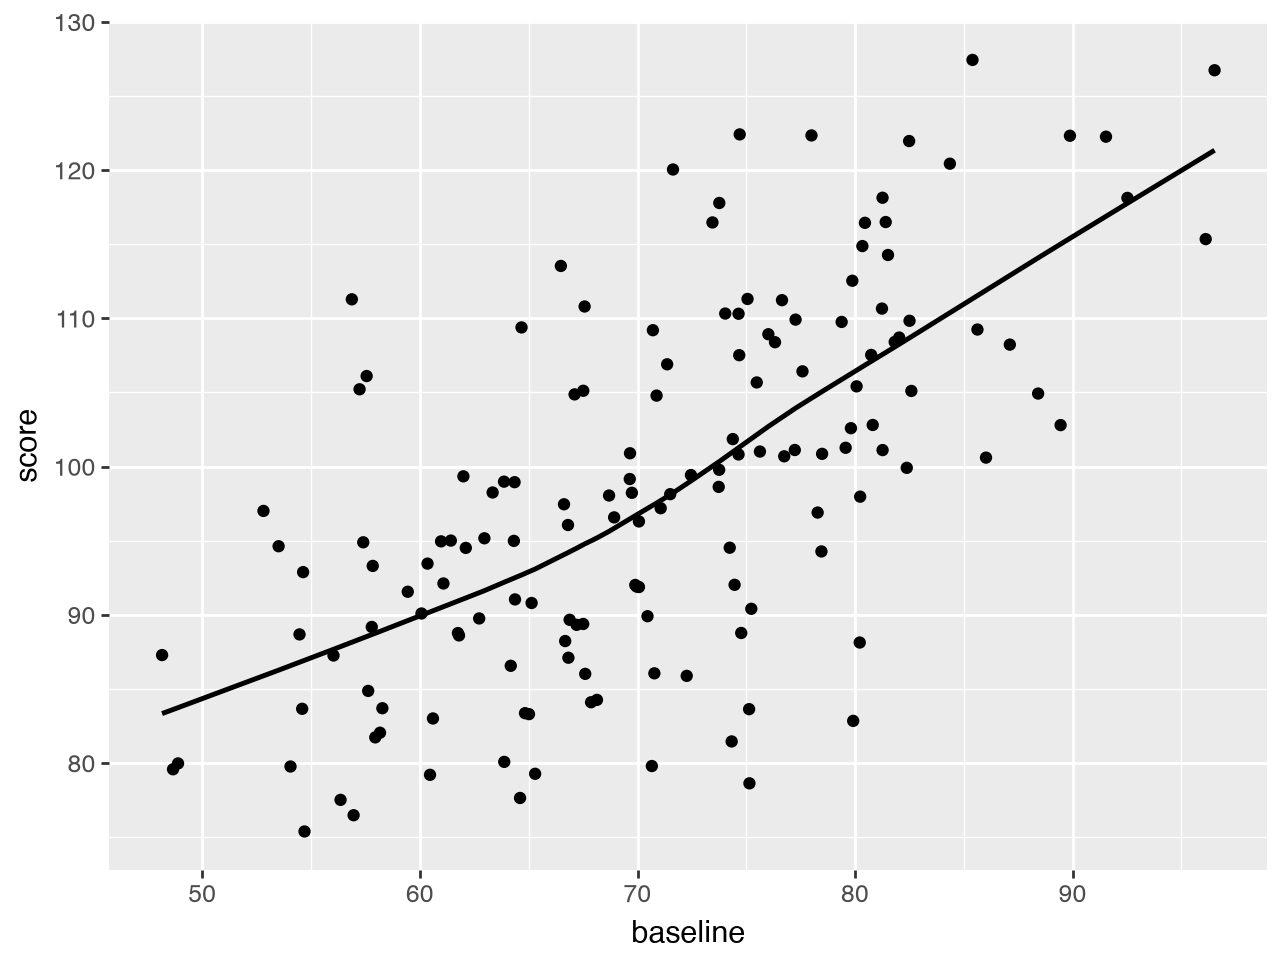

In [34]:
(
    ggplot(
        df,
        aes(
            x="baseline",
            y="score"
        )
    )
    + geom_point()
    + geom_smooth()
)

What information does the second geometry add?

It adds a smoothing line to the data.

## Part 19

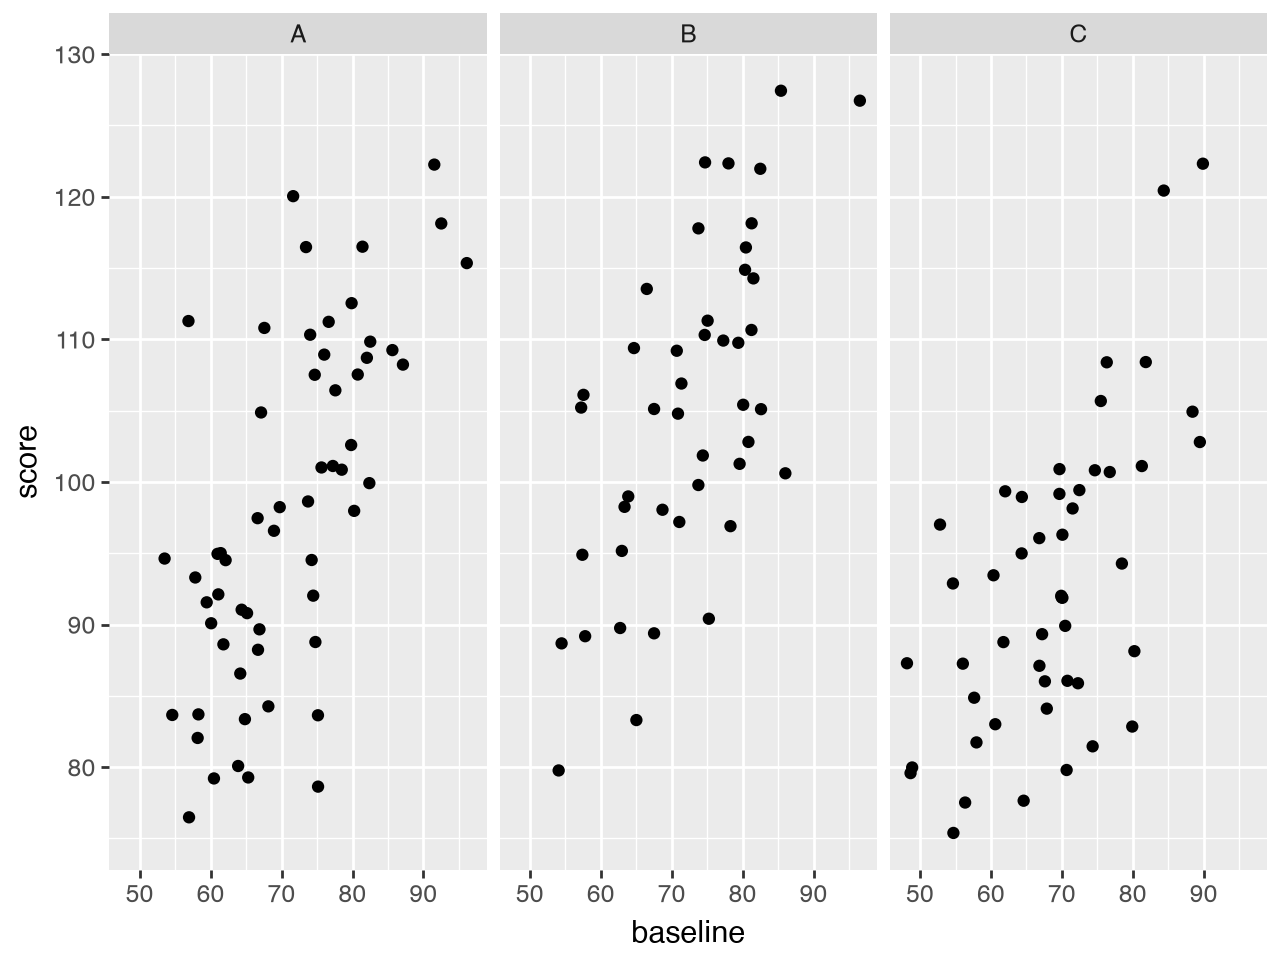

In [35]:
(
    ggplot(
        df,
        aes(
            x="baseline",
            y="score"
        )
    )
    + geom_point()
    + facet_wrap("group")
)

Compare this with mapping group to color.

The facet plots groups seperately making it easier to spot differences when there is overlap.

## Part 20

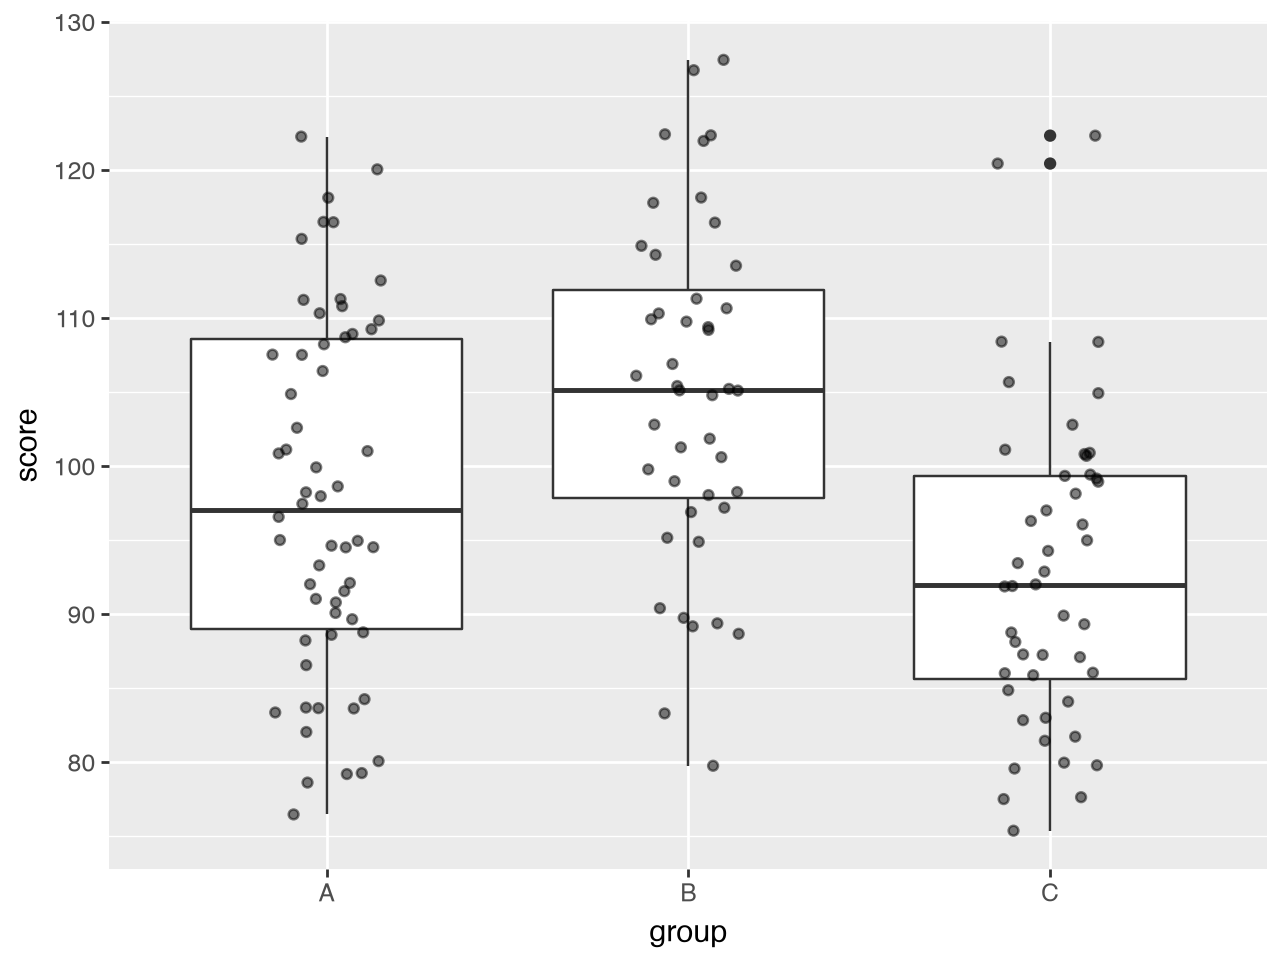

In [36]:
(
    ggplot(
        df,
        aes(
            x="group",
            y="score"
        )
    )
    + geom_boxplot()
    + geom_jitter(
        width=0.15,
        alpha=0.5
    )
)

Which layer provides a summary? Which shows raw observations?

The first layer (geom_boxplot) provides a summary and the secons layer (geom_jitter) shows the raw data.

## Part 21

Create a cluttered plot using too many visual encodings such as color, size, and shape.

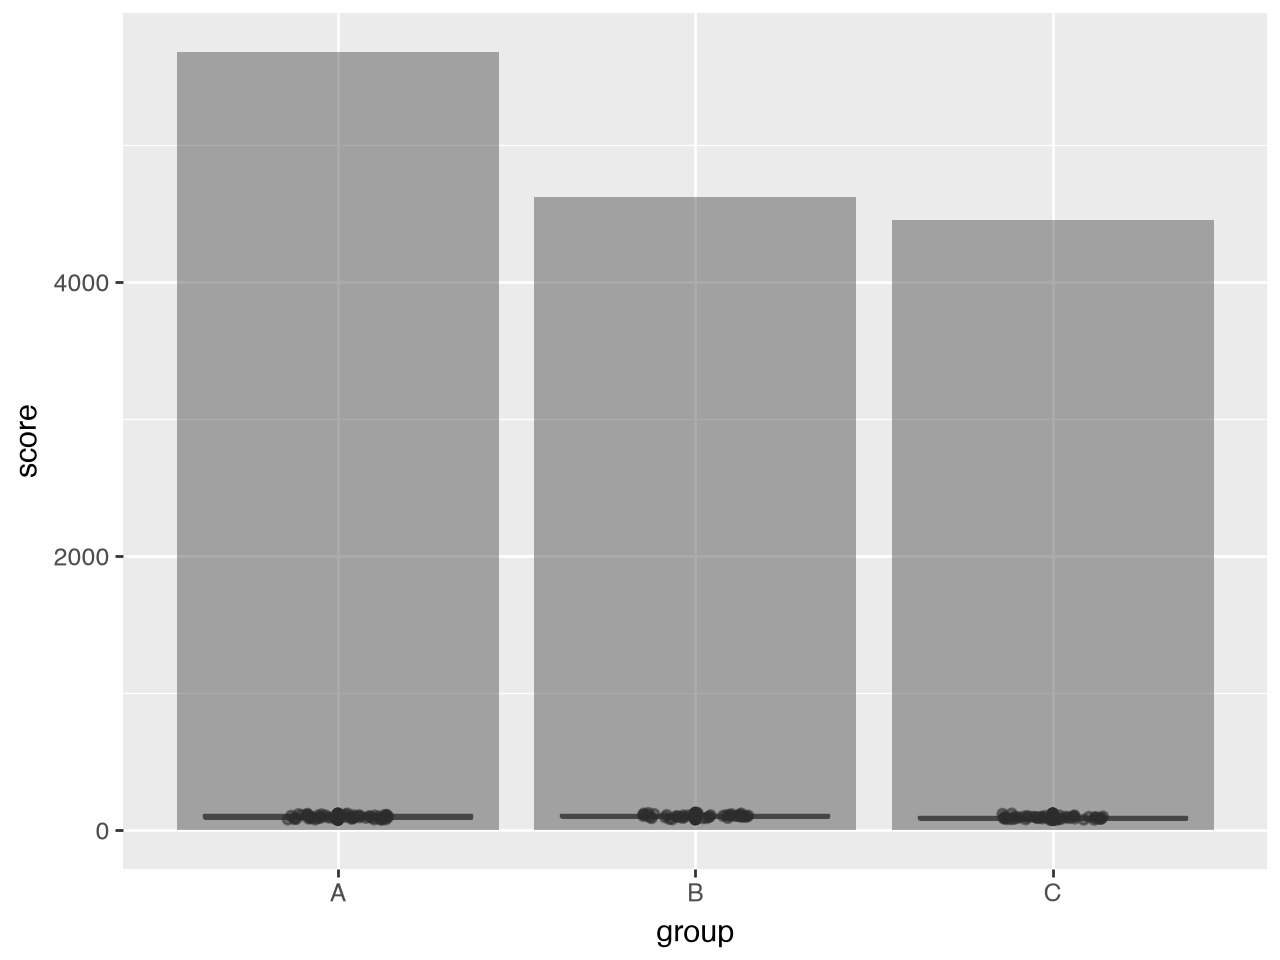

In [42]:
import plotnine as gg

(
    ggplot(
        df,
        aes(
            x="group",
            y="score",
        )
    )
    + geom_boxplot()
    + geom_jitter(
        width=0.15,
        alpha=0.5,
    )
    + geom_point()
    + gg.geom_col(alpha=0.5)
    
)

Then answer:

Is more encoded information always better?

Which encodings are useful?

Which would you remove?

Simplify the plot.